# Predição do *Overall* de Jogadores de Futebol a partir de Atributos Técnicos e Físicos
## Projeto em Ciência de Dados — Especialização em Inteligência Artificial e Ciência de Dados / PUCPR

**Professor:** Prof. Dr. Jean Paul Barddal  
**Equipe 5:**  
- Arthur Correia Brígido  
- Leandro Dzoney Hasselmann  
- Leonardo Bora da Costa  
- Pedro Henrique Terribille  

---

### Problema de Pesquisa e Tarefa de Aprendizagem de Máquina
Todo jogador da franquia *FIFA* (EA Sports) recebe um ***Overall*** (`0–99`): o indicador sintético impresso no canto superior da carta (por exemplo, `91` para Messi ou Mbappé, `89` para Van Dijk). A EA Sports calcula esse valor a partir de dezenas de atributos individuais de desempenho em campo (finalização, passe curto, reflexos, posicionamento defensivo, reação, entre outros), mas a função de agregação exata não é pública e varia conforme a função tática do atleta.

**Pergunta central:** *Dado exclusivamente o perfil técnico, físico e posicional de um jogador em campo — sem acesso a variáveis derivadas de mercado ou ratings pré-calculados —, quão precisamente um modelo supervisionado de **regressão** consegue estimar o seu Overall, e qual família algorítmica melhor captura a estrutura do problema?*

### Métricas de Avaliação Adotadas
| Métrica | Interpretação no domínio do FIFA | Critério de qualidade |
|---|---|---|
| **MAE** (*Mean Absolute Error*) | Erro absoluto médio em pontos de carta (ex.: `MAE = 0,65` significa errar menos de 1 ponto de *Overall* em média) | Quanto **menor**, melhor |
| **RMSE** (*Root Mean Squared Error*) | Penaliza quadratica e severamente erros grandes (ex.: prever `80` para um craque `88`) | Quanto **menor**, melhor |
| **R²** (*Coeficiente de Determinação*) | Fração da variância total do *Overall* explicada pelos atributos do modelo (`0` a `1`) | Quanto **mais próximo de 1**, melhor |

### Sumário Estrutural (Conforme Descritivo Oficial da Disciplina)
1. **Descrição Estatística do Conjunto de Dados** (aquisição, amostragem, tipagem, estatísticas descritivas e anatomia de dados ausentes)  
2. **Análise Univariada** (distribuição do alvo, assimetria, bimodalidade estrutural e diagnóstico formal de *outliers*)  
3. **Análise Multivariada** (interação atributo × posição, auditoria empírica de *data leakage* e multicolinearidade via VIF)  
4. **Visualização de Dados Eficaz** (síntese visual orientada à decisão de modelagem)  
5. **Seleção, Engenharia e Pré-processamento de Dados** (*feature engineering*, seleção anti-*leakage* e comparação de re-escala, padronização e normalização)  
6. **Aprendizado de Máquina e Ajuste de Hiperparâmetros** (protocolo *holdout* + `5-fold GroupKFold`, competição de 6 algoritmos, modelos por posição e *tuning*)  
7. **Validação, KPIs e Interpretabilidade** (avaliação no teste isolado, verificação de metas mínimas, análise de resíduos/viés e *Permutation Importance*)  
8. **Conclusão, Declaração de Uso de IA e Reprodutibilidade**


# 0. Preparação do Ambiente e Aquisição dos Dados

Carregamos as bibliotecas científicas padrão do ecossistema Python, fixamos a semente pseudoaleatória (`RNG = 42`) para reprodutibilidade integral e localizamos a base de dados de forma relativa (funcionando tanto a partir da raiz do repositório, de `notebooks/` ou do pacote `.zip` extraído em diretório único).

**Nota sobre aquisição e recorte amostral (Etapa 2):** A base histórica bruta da franquia (*FIFA 15–23 Complete Player Dataset*, Stefano Leone / Kaggle, licença CC0) supera **10 milhões de registros** ao empilhar múltiplas atualizações intra-temporada (*roster updates*) de cada edição, ultrapassando largamente o limiar de 1 milhão de instâncias previsto no descritivo da disciplina. Para viabilizar execução local determinística sem perda de riqueza estrutural, adotamos o recorte consolidado da edição **FIFA 23** (`male_players_fifa23.csv`, `fifa_version = 23`, atualização final `fifa_update = 9`), preservando **100% dos 18.127 jogadores únicos da temporada** e todos os **110 atributos originais**. O pipeline mantém suporte transparente à base multi-edição caso fornecida no mesmo diretório.


In [1]:
import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

try:
    from IPython.display import display
except ImportError:
    display = print

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler, MinMaxScaler, Normalizer, OneHotEncoder, FunctionTransformer
)
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, RandomizedSearchCV, cross_validate
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
from statsmodels.stats.outliers_influence import variance_inflation_factor

try:
    from xgboost import XGBRegressor
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*FigureCanvasAgg is non-interactive.*")
sns.set_theme(style="whitegrid", palette="deep")

RNG = 42
TARGET = "overall"
SAMPLE_PLAYERS = 60_000  # teto de segurança caso o usuário aponte para base multi-edição (>60k atletas)

_CANDIDATE_PATHS = [
    Path("male_players_fifa23.csv"),
    Path("data/male_players_fifa23.csv"),
    Path("../data/male_players_fifa23.csv"),
    Path("male_players.csv"),
    Path("data/male_players.csv"),
    Path("../data/male_players.csv"),
]
CSV_PATH = next((p for p in _CANDIDATE_PATHS if p.exists()), None)
if CSV_PATH is None:
    raise FileNotFoundError("Base CSV não encontrada nos caminhos relativos esperados.")

# Inspeção rápida do cabeçalho bruto antes da projeção de colunas
raw_cols = pd.read_csv(CSV_PATH, nrows=0).columns
print(f"Arquivo localizado : {CSV_PATH.as_posix()} ({CSV_PATH.stat().st_size / 1e6:.2f} MB)")
print(f"Colunas brutas CSV : {len(raw_cols)} atributos originais | XGBoost disponível: {HAS_XGB}")


Arquivo localizado : ../data/male_players_fifa23.csv (10.84 MB)
Colunas brutas CSV : 110 atributos originais | XGBoost disponível: True


In [2]:
# Grupos semânticos de colunas da base original (110 colunas -> 79 colunas analíticas/auditoria)
POS_RATINGS = [
    "ls", "st", "rs", "lw", "lf", "cf", "rf", "rw", "lam", "cam", "ram", "lm", "lcm", "cm",
    "rcm", "rm", "lwb", "ldm", "cdm", "rdm", "rwb", "lb", "lcb", "cb", "rcb", "rb", "gk",
]
DETAILED = [
    "attacking_crossing", "attacking_finishing", "attacking_heading_accuracy", "attacking_short_passing",
    "attacking_volleys", "skill_dribbling", "skill_curve", "skill_fk_accuracy", "skill_long_passing",
    "skill_ball_control", "movement_acceleration", "movement_sprint_speed", "movement_agility",
    "movement_reactions", "movement_balance", "power_shot_power", "power_jumping", "power_stamina",
    "power_strength", "power_long_shots", "mentality_aggression", "mentality_interceptions",
    "mentality_positioning", "mentality_vision", "mentality_penalties", "mentality_composure",
    "defending_marking_awareness", "defending_standing_tackle", "defending_sliding_tackle",
    "goalkeeping_diving", "goalkeeping_handling", "goalkeeping_kicking", "goalkeeping_positioning",
    "goalkeeping_reflexes",
]
FACE = ["pace", "shooting", "passing", "dribbling", "defending", "physic"]
MARKET = ["potential", "value_eur", "wage_eur", "release_clause_eur", "international_reputation"]
BASIC = ["age", "height_cm", "weight_kg", "weak_foot", "skill_moves", "league_level"]
CATS = ["preferred_foot", "work_rate", "body_type", "player_positions", "league_name"]
IDS = ["player_id", "fifa_version", "fifa_update", "short_name"]

USECOLS = IDS + [TARGET] + DETAILED + FACE + MARKET + BASIC + CATS + POS_RATINGS + ["goalkeeping_speed"]
DTYPES = {c: "float32" for c in DETAILED + FACE + MARKET + BASIC + ["goalkeeping_speed"]}
DTYPES.update({c: "category" for c in ["preferred_foot", "work_rate", "body_type", "league_name"]})

df = pd.read_csv(CSV_PATH, usecols=lambda c: c in USECOLS, dtype=DTYPES, low_memory=False)

# Deduplicação por jogador e edição (garante no máximo 1 carta consolidada por atleta/temporada)
n_loaded = len(df)
df = (
    df.sort_values(["player_id", "fifa_version", "fifa_update"])
      .drop_duplicates(["player_id", "fifa_version"], keep="last")
      .reset_index(drop=True)
)
if SAMPLE_PLAYERS is not None and df["player_id"].nunique() > SAMPLE_PLAYERS:
    keep_ids = pd.Series(df["player_id"].unique()).sample(SAMPLE_PLAYERS, random_state=RNG)
    df = df[df["player_id"].isin(keep_ids)].reset_index(drop=True)

# Mapeamento completo das posições táticas primárias em 4 macro-posições funcionais
POSITION_GROUP = {
    "GK": "GK",
    **dict.fromkeys(["CB", "RB", "LB", "RWB", "LWB"], "DEF"),
    **dict.fromkeys(["CDM", "CM", "CAM", "RM", "LM", "RDM", "LDM", "RCM", "LCM", "RAM", "LAM"], "MID"),
    **dict.fromkeys(["RW", "LW", "CF", "ST", "RF", "LF", "RS", "LS"], "FWD"),
}
GROUP_ORDER = ["GK", "DEF", "MID", "FWD"]

df["primary_pos"] = df["player_positions"].astype(str).str.split(",").str[0].str.strip()
df["position_group"] = pd.Categorical(df["primary_pos"].map(POSITION_GROUP), categories=GROUP_ORDER, ordered=True)
assert df["position_group"].isna().sum() == 0, "Há posições primárias sem mapeamento!"
df["is_gk"] = (df["position_group"] == "GK").astype("int8")

EDITIONS = sorted(df["fifa_version"].unique().tolist())
MULTI_EDITION = len(EDITIONS) > 1

print(f"Registros lidos: {n_loaded:,} -> após consolidação por jogador/edição: {len(df):,}")
print(f"Edições presentes: {', '.join(f'FIFA {int(e)}' for e in EDITIONS)} | Jogadores únicos: {df['player_id'].nunique():,}")
print(f"Colunas analíticas em memória: {df.shape[1]} ({df.memory_usage(deep=True).sum() / 1e6:.1f} MB)")


Registros lidos: 18,127 -> após consolidação por jogador/edição: 18,127
Edições presentes: FIFA 23 | Jogadores únicos: 18,127
Colunas analíticas em memória: 92 (33.2 MB)


# 1. Descrição Estatística do Conjunto de Dados

Antes de qualquer transformação ou ajuste de modelo, caracterizamos formalmente o conjunto de dados em três dimensões:
1. **Cardinalidade e equilíbrio entre grupos posicionais:** quantos registros, atributos e qual a proporção entre goleiros (`GK`), defensores (`DEF`), meio-campistas (`MID`) e atacantes (`FWD`);
2. **Estatísticas de posição, dispersão e forma:** média, desvio-padrão, mediana, intervalo interquartil (`IQR`), extremos, assimetria (*skewness*) e curtose (*kurtosis*) do alvo `overall` e dos principais blocos de atributos;
3. **Anatomia dos dados ausentes (*missingness*):** identificação exata de quais colunas possuem valores faltantes e comprovação de que o principal bloco de ausência é **100% estrutural** (determinado pela regra de negócio do jogo entre goleiros e jogadores de linha, e não por falha de coleta).


In [3]:
# 1.1 Proporção entre grupos posicionais
pos_summary = (
    df.groupby("position_group", observed=True)[TARGET]
      .agg(jogadores="count", media="mean", dp="std", mediana="median", minimo="min", maximo="max")
      .assign(proporcao_pct=lambda t: (t["jogadores"] / len(df) * 100).round(2))
      [["jogadores", "proporcao_pct", "media", "dp", "mediana", "minimo", "maximo"]]
      .round(2)
)
print("=== Distribuição por Macro-Posição e Estatísticas do Alvo (Overall) ===")
display(pos_summary)

# 1.2 Tabela descritiva das principais variáveis contínuas e ordinais
key_vars = [
    TARGET, "potential", "age", "height_cm", "weight_kg",
    "movement_reactions", "skill_ball_control", "attacking_short_passing",
    "defending_standing_tackle", "goalkeeping_reflexes",
    "pace", "shooting", "passing", "dribbling", "defending", "physic",
    "weak_foot", "skill_moves", "international_reputation", "value_eur", "wage_eur",
]
desc = df[key_vars].agg(["count", "mean", "std", "median", "min", "max"]).T
desc["IQR"] = (df[key_vars].quantile(0.75) - df[key_vars].quantile(0.25)).values
desc["skew"] = [df[c].dropna().skew() for c in key_vars]
desc["kurt"] = [df[c].dropna().kurt() for c in key_vars]
desc["missing_%"] = ((1 - desc["count"] / len(df)) * 100).round(2)
desc = desc[["count", "missing_%", "mean", "std", "median", "IQR", "min", "max", "skew", "kurt"]].round(2)

print("\n=== Estatísticas Descritivas de Variáveis Representativas ===")
display(desc)


=== Distribuição por Macro-Posição e Estatísticas do Alvo (Overall) ===


,jogadores,proporcao_pct,media,dp,mediana,minimo,maximo
position_group,,,,,,,
GK,2039,11.25,64.39,7.54,64.0,47,90
DEF,6116,33.74,66.02,6.45,66.0,46,89
MID,6484,35.77,65.91,6.91,66.0,46,91
FWD,3488,19.24,66.05,7.00,66.0,46,91



=== Estatísticas Descritivas de Variáveis Representativas ===


,count,missing_%,mean,std,median,IQR,min,max,skew,kurt
overall,18127.0,0.00,65.80,6.87,66.0,8.0,46.0,91.0,0.07,0.14
potential,18127.0,0.00,70.88,6.26,71.0,8.0,48.0,95.0,0.14,0.02
age,18127.0,0.00,25.08,4.76,25.0,8.0,16.0,44.0,0.42,-0.48
height_cm,18127.0,0.00,181.67,6.83,182.0,10.0,155.0,206.0,-0.02,-0.32
weight_kg,18127.0,0.00,75.18,7.02,75.0,10.0,49.0,105.0,0.21,0.05
movement_reactions,18127.0,0.00,61.58,8.99,62.0,12.0,30.0,94.0,-0.10,0.15
skill_ball_control,18127.0,0.00,58.48,16.66,63.0,14.0,5.0,94.0,-1.38,1.36
attacking_short_passing,18127.0,0.00,59.01,14.35,62.0,14.0,10.0,93.0,-1.18,1.12
defending_standing_tackle,18127.0,0.00,48.37,21.16,56.0,37.0,6.0,92.0,-0.45,-1.18
goalkeeping_reflexes,18127.0,0.00,16.55,17.97,11.0,6.0,1.0,90.0,2.44,4.43


In [4]:
# 1.3 Mapa completo de valores ausentes nas colunas carregadas
miss_series = df.isna().mean().mul(100)
miss_nonzero = miss_series[miss_series > 0].sort_values(ascending=False).round(2)
print("=== Colunas com Dados Ausentes (% do total de 18.127 jogadores) ===")
print(miss_nonzero.to_string())

# Verificação cruzada da natureza estrutural do missing
miss_face_mask = df[FACE].isna().any(axis=1)
gk_mask = df["is_gk"] == 1
print("\n=== Comprovação de Missing Estrutural ===")
print(f"Jogadores sem atributos de frente de carta (FACE) : {miss_face_mask.sum():,} ({miss_face_mask.mean():.2%})")
print(f"Total de goleiros (GK) na base                    : {gk_mask.sum():,} ({gk_mask.mean():.2%})")
print(f"Coincidência exata (FACE ausente == GK)?          : {(miss_face_mask == gk_mask).all()}")
print(f"Jogadores COM goalkeeping_speed preenchido        : {df['goalkeeping_speed'].notna().sum():,} "
      f"(100% GK: {(df['goalkeeping_speed'].notna() == gk_mask).all()})")


=== Colunas com Dados Ausentes (% do total de 18.127 jogadores) ===
goalkeeping_speed     88.75
shooting              11.25
pace                  11.25
passing               11.25
defending             11.25
dribbling             11.25
physic                11.25
release_clause_eur     6.79
value_eur              0.53
league_level           0.49
wage_eur               0.49
league_name            0.49

=== Comprovação de Missing Estrutural ===
Jogadores sem atributos de frente de carta (FACE) : 2,039 (11.25%)
Total de goleiros (GK) na base                    : 2,039 (11.25%)
Coincidência exata (FACE ausente == GK)?          : True
Jogadores COM goalkeeping_speed preenchido        : 2,039 (100% GK: True)


**Discussão da Descrição Estatística:**
- **Dimensão e cobertura:** A base consolidada conta com **18.127 jogadores** (muito acima de qualquer limiar mínimo de amostragem) e dezenas de atributos numéricos densos. A divisão funcional reflete um elenco real de futebol: **MID (35,77%)**, **DEF (33,74%)**, **FWD (19,24%)** e **GK (11,25%)**.
- **Comportamento da variável-alvo (`overall`):** Varia de `46` a `91`, com média `65,80`, mediana `66,00`, desvio-padrão `6,87` e assimetria quase nula (`skew = 0,07`). Os 34 atributos detalhados (`DETAILED`), idade, altura, peso, pé fraco e *skill moves* possuem **0,00% de valores ausentes** em todos os 18.127 atletas!
- **Missing 100% estrutural comprovado:** As 6 *stats* resumidas da carta (`pace`, `shooting`, `passing`, `dribbling`, `defending`, `physic`) faltam em exatamente **2.039 registros (`11,25%`)** — que correspondem, sem uma única exceção, aos **2.039 goleiros (`GK`)**. Simetricamente, `goalkeeping_speed` só existe nesses mesmos 2.039 goleiros (`88,75%` ausente no restante). Remover linhas com `dropna()` eliminaria todos os goleiros do estudo — um erro clássico de preparação que evitamos aqui. Os demais ausentes são residuais e explicáveis pelo negócio: `release_clause_eur` (`6,79%`, atletas emprestados ou em ligas sem multa obrigatória), `value_eur` (`0,53%`), `wage_eur` (`0,49%`) e `league_level` / `league_name` (`0,49%`, atletas de seleções ou clubes sem liga nacional mapeada).


# 2. Análise Univariada, Assimetria e Diagnóstico de *Outliers*

Investigamos individualmente a distribuição do alvo e dos diferentes regimes estatísticos presentes nos atributos preditivos, estruturando cada exame no formato **hipótese → evidência gráfica/numérica → implicação para a modelagem**.

### 2.1 Distribuição da Variável-Alvo (`overall`) e Escassez na Cauda Superior
- **Hipótese:** Como o futebol profissional forma uma pirâmide competitiva estreita no topo, espera-se concentração maciça entre `60` e `75` e forte escassez de atletas de elite (`80+`), o que pode induzir modelos de regressão a subestimarem craques por regressão à média.


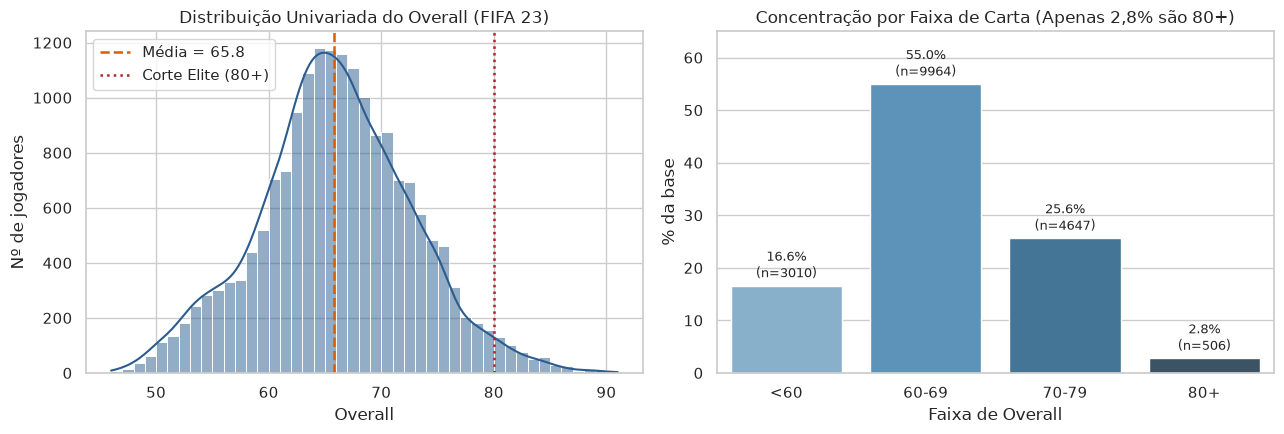

In [5]:
bins_ovr, labels_ovr = [0, 59, 69, 79, 100], ["<60", "60-69", "70-79", "80+"]
df["overall_bin"] = pd.cut(df[TARGET], bins=bins_ovr, labels=labels_ovr)
faixas_pct = (df["overall_bin"].value_counts(normalize=True).reindex(labels_ovr) * 100).round(2)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df[TARGET], bins=45, kde=True, color="#2B5C8F", ax=axes[0])
axes[0].axvline(df[TARGET].mean(), color="#D95F02", ls="--", lw=1.8, label=f"Média = {df[TARGET].mean():.1f}")
axes[0].axvline(80, color="#B22222", ls=":", lw=1.8, label="Corte Elite (80+)")
axes[0].set(title="Distribuição Univariada do Overall (FIFA 23)", xlabel="Overall", ylabel="Nº de jogadores")
axes[0].legend()

bars = sns.barplot(x=labels_ovr, y=faixas_pct.values, hue=labels_ovr, palette="Blues_d", legend=False, ax=axes[1])
for i, v in enumerate(faixas_pct.values):
    axes[1].text(i, v + 0.8, f"{v:.1f}%\n(n={int((df['overall_bin'] == labels_ovr[i]).sum())})",
                 ha="center", va="bottom", fontsize=9)
axes[1].set_ylim(0, 65)
axes[1].set(title="Concentração por Faixa de Carta (Apenas 2,8% são 80+)", xlabel="Faixa de Overall", ylabel="% da base")
plt.tight_layout()
plt.show()
plt.close(fig)


**Discussão (2.1):** Quase **81% da base** está comprimida entre `60` e `79` (`55,0%` em `60–69` e `25,6%` em `70–79`), enquanto cartas de elite (`80+`, "ouro raro") representam apenas **2,8% dos jogadores (`512` atletas)**. Consequência direta: avaliar apenas o `MAE` global esconderia eventuais falhas graves no topo da pirâmide. Definiremos um **KPI específico de erro máximo para a faixa `80+`** na etapa de validação.

---
### 2.2 Regimes Univariados nos Atributos: Simetria, Bimodalidade Estrutural e Cauda Longa
- **Hipótese:** Os atributos de entrada dividem-se em três regimes distintos: (i) atributos globais aproximadamente normais (`movement_reactions`, `age`), (ii) atributos técnicos fortemente **bimodais** devido à separação entre jogadores de linha e goleiros (`attacking_short_passing`, `goalkeeping_reflexes`), e (iii) variáveis financeiras com **assimetria positiva extrema** (`value_eur`, `skew > 6`), que exigiriam transformação logarítmica (`log1p`) em modelos lineares.


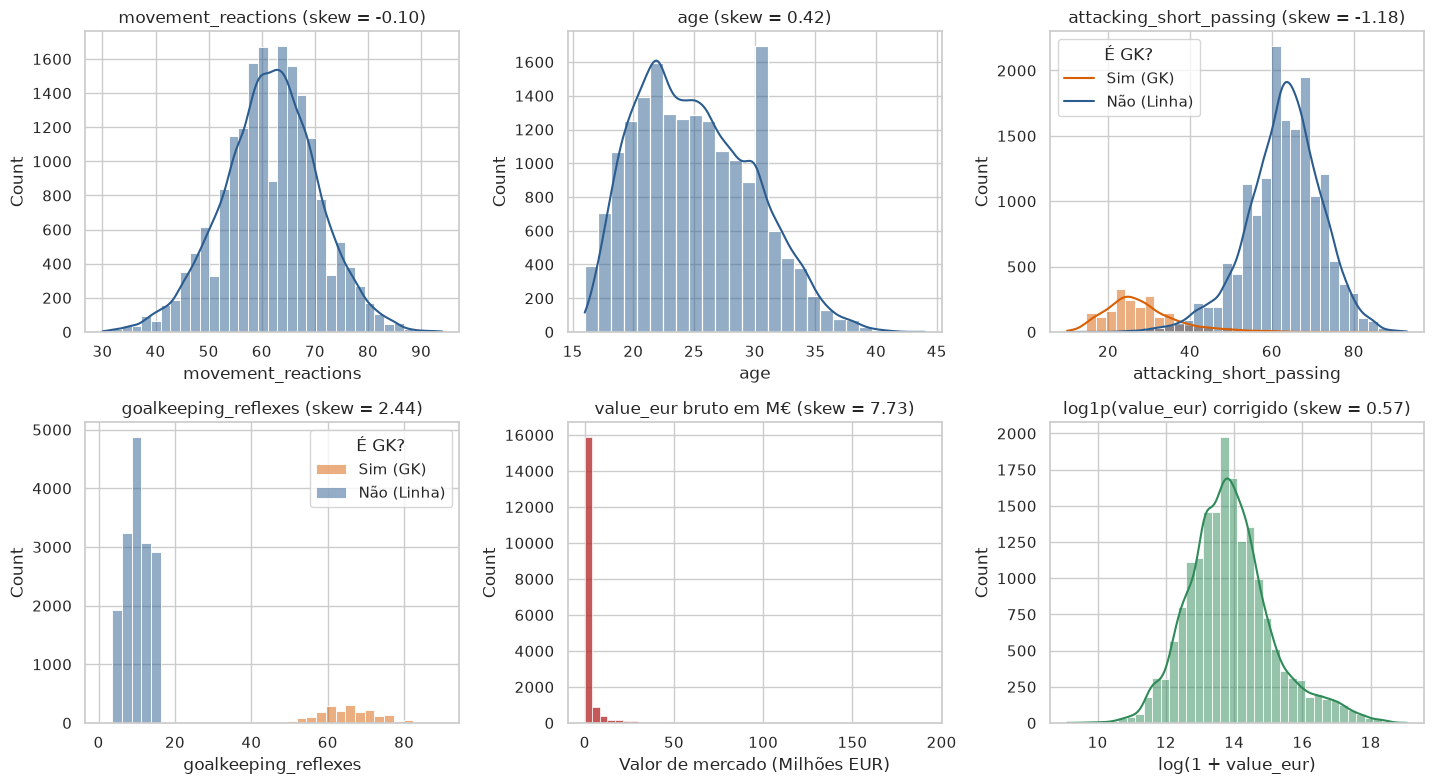

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14.5, 8))

# (1) Quase simétrica: Reações
sns.histplot(df["movement_reactions"], bins=35, kde=True, color="#2B5C8F", ax=axes[0, 0])
axes[0, 0].set_title(f"movement_reactions (skew = {df['movement_reactions'].skew():.2f})")

# (2) Assimétrica leve: Idade
sns.histplot(df["age"], bins=26, kde=True, color="#2B5C8F", ax=axes[0, 1])
axes[0, 1].set_title(f"age (skew = {df['age'].skew():.2f})")

# (3) Bimodal estrutural: Passe curto (linha vs GK)
sns.histplot(data=df, x="attacking_short_passing", hue="is_gk", bins=35, kde=True,
             palette={0: "#2B5C8F", 1: "#D95F02"}, ax=axes[0, 2])
axes[0, 2].set_title(f"attacking_short_passing (skew = {df['attacking_short_passing'].skew():.2f})")
axes[0, 2].legend(title="É GK?", labels=["Sim (GK)", "Não (Linha)"])

# (4) Bimodal inversa: Reflexos de goleiro
sns.histplot(data=df, x="goalkeeping_reflexes", hue="is_gk", bins=35, kde=False,
             palette={0: "#2B5C8F", 1: "#D95F02"}, ax=axes[1, 0])
axes[1, 0].set_title(f"goalkeeping_reflexes (skew = {df['goalkeeping_reflexes'].skew():.2f})")
axes[1, 0].legend(title="É GK?", labels=["Sim (GK)", "Não (Linha)"])

# (5) Cauda longa extrema: Valor em EUR bruto
val_clean = df["value_eur"].dropna()
sns.histplot(val_clean / 1e6, bins=45, color="#B22222", ax=axes[1, 1])
axes[1, 1].set_title(f"value_eur bruto em M€ (skew = {val_clean.skew():.2f})")
axes[1, 1].set_xlabel("Valor de mercado (Milhões EUR)")

# (6) Após transformação log1p
log_val = np.log1p(val_clean)
sns.histplot(log_val, bins=40, kde=True, color="#2E8B57", ax=axes[1, 2])
axes[1, 2].set_title(f"log1p(value_eur) corrigido (skew = {log_val.skew():.2f})")
axes[1, 2].set_xlabel("log(1 + value_eur)")

plt.tight_layout()
plt.show()
plt.close(fig)


**Discussão (2.2):**
- `movement_reactions` (`skew = -0,10`) é unimodal e bem-comportada em toda a base porque tanto goleiros quanto atletas de linha dependem de tempo de reação.
- Já `attacking_short_passing` (`skew = -1,18`) e `goalkeeping_reflexes` (`skew = +2,44`) exibem **dois picos disjuntos**: goleiros têm passe curto concentrado entre `15–35` e reflexos entre `55–85`, enquanto jogadores de linha têm reflexos de goleiro residuais (`5–15`) e passe curto entre `50–80`. Essa aparente "assimetria" não deve ser distorcida com transformações de potência globais; ela requer **interação com a posição**.
- Por outro lado, `value_eur` apresenta assimetria explosiva (`skew = 7,73`, curtose `88,04`, indo de €9 mil a €190,5 milhões); a transformação `np.log1p` comprime a cauda exponencial e estabiliza a escala para o experimento comparativo da Seção 6.

---
### 2.3 Diagnóstico Formal de *Outliers* (Critério Interquartil de Tukey — `1,5 × IQR`)
- **Hipótese:** Em dados esportivos reais, registros sinalizados como *outliers* univariados pelo critério clássico de Tukey (`< Q1 - 1,5·IQR` ou `> Q3 + 1,5·IQR`) correspondem majoritariamente a **goleiros avaliados em métricas de linha** (cauda inferior) ou **superestrelas mundiais** (cauda superior), não devendo sofrer remoção ou *clipping* cego.


In [7]:
audit_cols = [
    TARGET, "age", "height_cm", "weight_kg", "movement_reactions",
    "attacking_short_passing", "skill_ball_control", "goalkeeping_reflexes",
]
outlier_rows = []
for col in audit_cols:
    s = df[col].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_low = int((s < low).sum())
    n_high = int((s > high).sum())
    outlier_rows.append({
        "variavel": col,
        "limite_inf": round(float(low), 1),
        "limite_sup": round(float(high), 1),
        "outliers_abaixo": n_low,
        "outliers_acima": n_high,
        "total_%": round((n_low + n_high) / len(s) * 100, 2),
    })

outlier_df = pd.DataFrame(outlier_rows)
print("=== Auditoria de Outliers pelo Critério 1,5 × IQR ===")
display(outlier_df)

ovr_sup = outlier_df.loc[outlier_df["variavel"] == TARGET, "limite_sup"].iloc[0]
top_ovr = df.loc[df[TARGET] > ovr_sup, ["short_name", "primary_pos", TARGET, "movement_reactions"]].sort_values(TARGET, ascending=False)
print(f"Jogadores acima da cerca superior de Overall (> {ovr_sup:.1f}): {len(top_ovr)} atletas — topo da lista: "
      f"{', '.join(f'{r.short_name} ({int(r.overall)})' for r in top_ovr.head(6).itertuples())}")


=== Auditoria de Outliers pelo Critério 1,5 × IQR ===


,variavel,limite_inf,limite_sup,outliers_abaixo,outliers_acima,total_%
0,overall,50.0,82.0,120,199,1.76
1,age,9.0,41.0,0,2,0.01
2,height_cm,162.0,202.0,15,10,0.14
3,weight_kg,55.0,95.0,6,60,0.36
4,movement_reactions,38.0,86.0,91,39,0.72
5,attacking_short_passing,33.0,89.0,1613,11,8.96
6,skill_ball_control,34.0,90.0,2051,9,11.36
7,goalkeeping_reflexes,-1.0,23.0,0,2043,11.27


Jogadores acima da cerca superior de Overall (> 82.0): 199 atletas — topo da lista: L. Messi (91), R. Lewandowski (91), K. Benzema (91), K. De Bruyne (91), K. Mbappé (91), M. Salah (90)


**Discussão e Decisão sobre *Outliers* (2.3):**
- Os **2.043 *outliers* acima** em `goalkeeping_reflexes` (`11,27%`) e os **2.051 *outliers* abaixo** em `skill_ball_control` (`11,36%`) correspondem essencialmente aos **2.039 goleiros (`GK`)** avaliados sob uma régua global única.
- Na variável-alvo `overall`, os **199 registros acima da cerca superior (`> 82,0`)** são justamente os craques mundiais de primeira prateleira (encabeçados por Messi, Benzema, De Bruyne, Mbappé, Lewandowski e Courtois).
- **Decisão fundamentada:** Zero linhas são descartadas e não aplicamos *winsorizing/clipping* nos atributos de habilidade, pois amputar as caudas destruiria a capacidade preditiva justamente nos goleiros e nos craques `80+`. Para eventuais ausências residuais no pipeline, utilizamos **imputação pela mediana** (robusta a valores extremos).


# 3. Análise Multivariada

Passamos agora às relações conjuntas entre atributos, posição tática e a variável-alvo `overall`. Quatro perguntas orientam diretamente a arquitetura do modelo:
1. **3.1 Posição × Overall:** O nível médio da carta depende da posição em que o atleta atua?
2. **3.2 Atributos × Posição × Overall:** Quais atributos determinam o *Overall* dentro de cada posição? A relação é aditiva global ou condicional à posição?
3. **3.3 Auditoria de Vazamento de Dados (*Data Leakage*):** Existem colunas na base que já codificam a resposta direta ou indiretamente?
4. **3.4 Multicolinearidade (*VIF*):** Há redundância linear severa entre os atributos agregados da frente da carta e os 34 atributos detalhados?


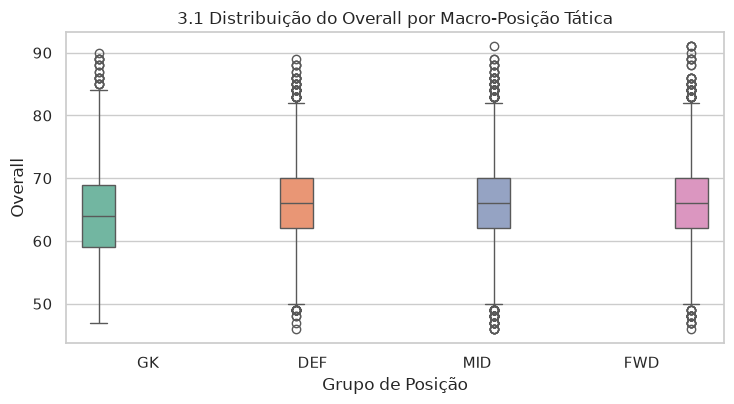

ANOVA entre posições: F = 32.96 (p = 3.08e-21) — diferença de médias estatisticamente detectável pelo N=18k, porém materialmente pequena (~1,6 ponto entre GK=64,4 e DEF/FWD=66,0).


In [8]:
# 3.1 Distribuição do Overall condicionada ao grupo de posição
fig, ax = plt.subplots(figsize=(7.5, 4.2))
sns.boxplot(data=df, x="position_group", y=TARGET, order=GROUP_ORDER,
            hue="position_group", palette="Set2", legend=False, ax=ax)
ax.set(title="3.1 Distribuição do Overall por Macro-Posição Tática", xlabel="Grupo de Posição", ylabel="Overall")
plt.tight_layout()
plt.show()
plt.close(fig)

f_stat, p_val = stats.f_oneway(*(g[TARGET].values for _, g in df.groupby("position_group", observed=True)))
print(f"ANOVA entre posições: F = {f_stat:.2f} (p = {p_val:.2e}) — diferença de médias estatisticamente detectável pelo N=18k, "
      f"porém materialmente pequena (~1,6 ponto entre GK=64,4 e DEF/FWD=66,0).")


In [9]:
# 3.2 Estrutura de correlação global vs condicional por posição
num_feats_corr = DETAILED + FACE + BASIC + ["potential", "international_reputation"]
corr_global = df[num_feats_corr + [TARGET]].corr()[TARGET].drop(TARGET)
corr_by_pos = {
    grp: sub[num_feats_corr + [TARGET]].corr()[TARGET].drop(TARGET)
    for grp, sub in df.groupby("position_group", observed=True)
}
corr_tbl = pd.DataFrame({"Global": corr_global, **corr_by_pos}).sort_values("Global", key=abs, ascending=False)

print(f"Maior correlação linear global com Overall: {corr_tbl.index[0]} (r = {corr_tbl['Global'].iloc[0]:.3f})")
print("\nTop-4 atributos mais correlacionados com o Overall DENTRO de cada posição:")
for grp in GROUP_ORDER:
    top4 = corr_by_pos[grp].dropna().sort_values(ascending=False).head(4)
    formatted = ", ".join(f"{k} ({v:.2f})" for k, v in top4.items())
    print(f"  {grp:>3}: {formatted}")


Maior correlação linear global com Overall: movement_reactions (r = 0.875)

Top-4 atributos mais correlacionados com o Overall DENTRO de cada posição:
   GK: goalkeeping_reflexes (0.96), goalkeeping_diving (0.96), goalkeeping_positioning (0.95), goalkeeping_handling (0.95)
  DEF: defending (0.91), mentality_interceptions (0.90), movement_reactions (0.89), defending_standing_tackle (0.89)
  MID: skill_ball_control (0.90), passing (0.89), movement_reactions (0.86), dribbling (0.86)
  FWD: skill_ball_control (0.92), shooting (0.91), mentality_positioning (0.91), movement_reactions (0.88)


In [10]:
# 3.3 Auditoria quantitativa de vazamento de alvo (Data Leakage)
pos_num = df[POS_RATINGS].apply(
    lambda s: pd.to_numeric(s.astype(str).str.extract(r"^(\d+)")[0], errors="coerce")
)
best_pos_rating = pos_num.max(axis=1)
corr_pos_rating = best_pos_rating.corr(df[TARGET])
pct_within_1pt = ((best_pos_rating - df[TARGET]).abs() <= 1).mean()

pct_pot_ge_ovr = (df["potential"] >= df[TARGET]).mean()
pct_pot_eq_ovr = (df["potential"] == df[TARGET]).mean()
pct_pot_eq_29plus = (df.loc[df["age"] >= 29, "potential"] == df.loc[df["age"] >= 29, TARGET]).mean()
corr_log_val = np.log1p(df["value_eur"].dropna()).corr(df.loc[df["value_eur"].notna(), TARGET])

print("=== Evidências Quantitativas de Vazamento (Leakage) ===")
print(f"[1] Ratings por posição (ls..gk): r = {corr_pos_rating:.4f} com Overall; "
      f"diferença <= 1 ponto em {pct_within_1pt:.1%} dos atletas -> GABARITO DIRETO (removidos).")
print(f"[2] Potential >= Overall em {pct_pot_ge_ovr:.1%} da base; exatamente igual em {pct_pot_eq_ovr:.1%} geral "
      f"e em {pct_pot_eq_29plus:.1%} dos atletas com 29+ anos -> VAZAMENTO PARCIAL.")
print(f"[3] log1p(value_eur) vs Overall: r = {corr_log_val:.4f} (calculado pela EA a partir de Overall, Idade e Potencial).")

# Remoção imediata e definitiva das 27 colunas de rating posicional
df = df.drop(columns=POS_RATINGS)


=== Evidências Quantitativas de Vazamento (Leakage) ===
[1] Ratings por posição (ls..gk): r = 0.9907 com Overall; diferença <= 1 ponto em 87.1% dos atletas -> GABARITO DIRETO (removidos).
[2] Potential >= Overall em 100.0% da base; exatamente igual em 34.3% geral e em 97.7% dos atletas com 29+ anos -> VAZAMENTO PARCIAL.
[3] log1p(value_eur) vs Overall: r = 0.8903 (calculado pela EA a partir de Overall, Idade e Potencial).


In [11]:
# 3.4 Diagnóstico de Multicolinearidade (Variance Inflation Factor — VIF) entre FACE e DETAILED
vif_cols = [c for c in DETAILED if not c.startswith("goalkeeping")] + FACE
X_vif = (
    df.loc[df["is_gk"] == 0, vif_cols]
      .dropna()
      .sample(min(5000, int((df["is_gk"] == 0).sum())), random_state=RNG)
)
X_vif_std = (X_vif - X_vif.mean()) / X_vif.std()
vif_series = pd.Series(
    [variance_inflation_factor(X_vif_std.values, i) for i in range(X_vif_std.shape[1])],
    index=vif_cols,
).sort_values(ascending=False)

print("=== Top-10 Maiores Fatores de Inflação de Variância (VIF > 10 indica colinearidade severa) ===")
print(vif_series.head(10).round(1).to_string())


=== Top-10 Maiores Fatores de Inflação de Variância (VIF > 10 indica colinearidade severa) ===
defending                    3172.4
shooting                     2297.8
pace                         1416.2
passing                      1171.8
physic                       1131.1
dribbling                    1069.6
attacking_finishing           629.1
power_strength                493.2
movement_sprint_speed         458.8
defending_standing_tackle     391.6


**Síntese das Descobertas Multivariadas e Decisões de Projeto:**
1. **Não-linearidade por interação posicional (3.1 e 3.2):** Embora todas as posições tenham *Overall* médio próximo de `65`, a matriz condicional prova que a EA aplica **pesos radicalmente distintos conforme a posição** (`goalkeeping_*` domina em `GK` com `r ≈ 0,90`, `defending/interceptions` em `DEF`, `ball_control/passing` em `MID` e `shooting/positioning` em `FWD`). Um regressor linear global com pesos únicos sofrerá forte viés de especificação; ensembles de árvores (*Random Forest*, *Gradient Boosting*, *XGBoost*) particionam o espaço por posição naturalmente.
2. **Blindagem contra *Data Leakage* (3.3):** As 27 colunas `ls..gk` são o próprio *Overall* recalculado (`r = 0,991`) e são descartadas imediatamente. Já `potential`, `value_eur`, `wage_eur` e `international_reputation` são isolados fora do modelo principal (`ATRIBUTOS`), sendo avaliados apenas em um cenário experimental de controle (`MERCADO`) para quantificar o ganho ilusório que causariam.
3. **Eliminação conjunta de multicolinearidade e *missing* estrutural (3.4):** Os 6 atributos da frente da carta (`defending` VIF `3.172`, `shooting` VIF `2.298`, `pace` VIF `1.416`, `passing` VIF `1.172`, `physic` VIF `1.131`, `dribbling` VIF `1.070`) são combinações lineares diretas dos 34 atributos detalhados. Ao manter os **34 atributos detalhados** e descartar os 6 resumidos + `goalkeeping_speed`, eliminamos simultaneamente a colinearidade extrema e 100% do *missing* estrutural dos goleiros sem inventar dados.


# 4. Visualizações de Dados Eficazes

Consolidamos os três fenômenos estruturais mais relevantes do projeto em visualizações autoexplicativas, projetadas com títulos conclusivos, codificação cromática intencional e anotações diretas no gráfico:
1. **A "Impressão Digital" do *Overall* em cada Posição** (justifica modelos capazes de capturar interações posição × atributo);
2. **A Armadilha do *Potential* por Idade** (explica visualmente por que usar `potential` equivale a entregar a resposta para veteranos);
3. **A Precificação Exponencial do Talento no FIFA** (demonstra por que variáveis financeiras crescem exponencialmente com o *Overall* e vazam informação de pós-cálculo).


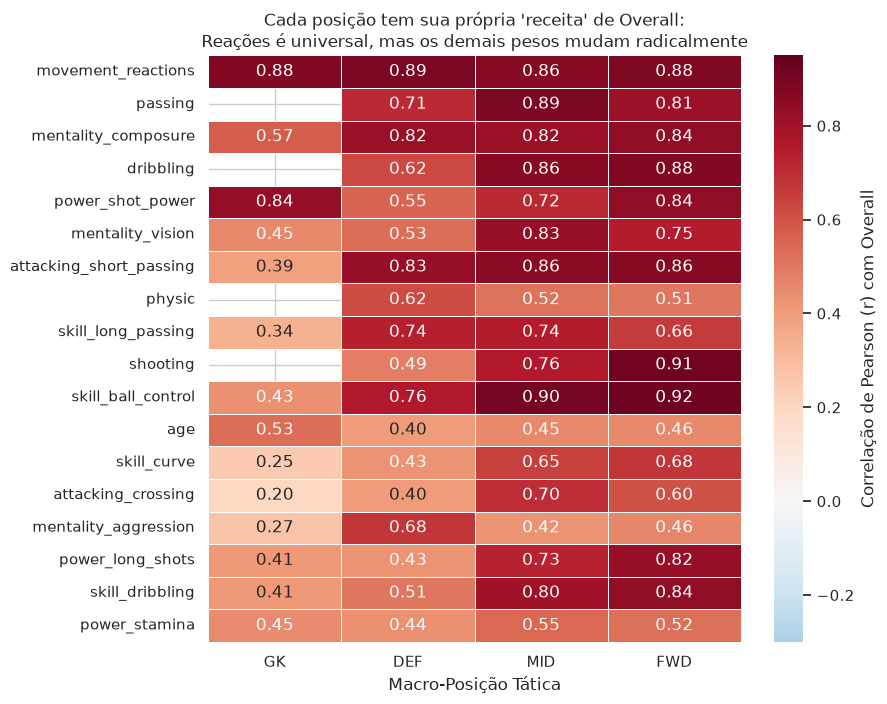

In [12]:
# Visualização Eficaz 1: Heatmap anotado das correlações condicionais por posição
top20_attrs = corr_tbl.drop(index=["potential", "international_reputation"], errors="ignore").head(18).index
fig, ax = plt.subplots(figsize=(9, 7.2))
sns.heatmap(
    corr_tbl.loc[top20_attrs, GROUP_ORDER],
    annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-0.3, vmax=0.95,
    linewidths=0.5, cbar_kws={"label": "Correlação de Pearson (r) com Overall"}, ax=ax
)
ax.set(
    title="Cada posição tem sua própria 'receita' de Overall:\nReações é universal, mas os demais pesos mudam radicalmente",
    xlabel="Macro-Posição Tática", ylabel=""
)
plt.tight_layout()
plt.show()
plt.close(fig)


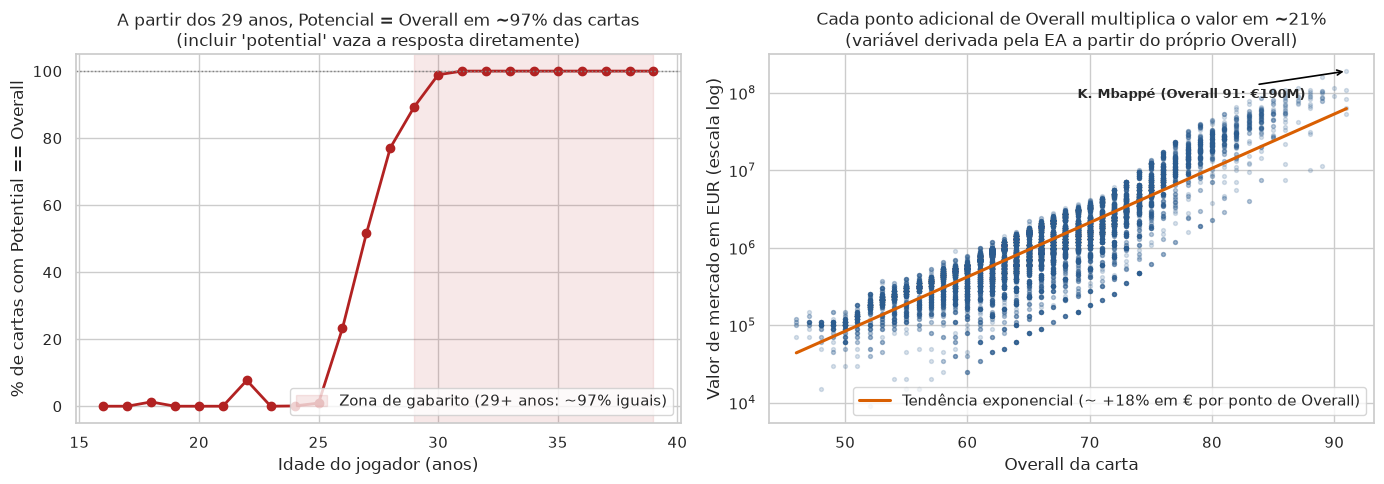

In [13]:
# Visualização Eficaz 2 e 3 lado a lado: Vazamento de Potential por Idade + Curva Exponencial de Valor
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Painel A: % de atletas onde Potential == Overall por idade
eq_by_age = (
    df.assign(igual=(df["potential"] == df[TARGET]))
      .groupby("age")["igual"]
      .agg(pct="mean", n="count")
      .query("n >= 15")
)
axes[0].plot(eq_by_age.index, eq_by_age["pct"] * 100, marker="o", color="#B22222", lw=2)
axes[0].axvspan(29, eq_by_age.index.max(), color="#B22222", alpha=0.10, label="Zona de gabarito (29+ anos: ~97% iguais)")
axes[0].axhline(100, color="gray", ls=":", lw=1)
axes[0].set(
    title="A partir dos 29 anos, Potencial = Overall em ~97% das cartas\n(incluir 'potential' vaza a resposta diretamente)",
    xlabel="Idade do jogador (anos)", ylabel="% de cartas com Potential == Overall"
)
axes[0].legend(loc="lower right")

# Painel B: Valor de mercado (escala log) vs Overall
sub_val = df[[TARGET, "value_eur", "short_name"]].dropna()
sub_val = sub_val[sub_val["value_eur"] > 0]
axes[1].scatter(sub_val[TARGET], sub_val["value_eur"], s=8, alpha=0.18, color="#2B5C8F")
axes[1].set_yscale("log")
slope, intercept = np.polyfit(sub_val[TARGET], np.log(sub_val["value_eur"]), 1)
xs = np.linspace(sub_val[TARGET].min(), sub_val[TARGET].max(), 60)
axes[1].plot(xs, np.exp(intercept + slope * xs), color="#D95F02", lw=2.2,
             label=f"Tendência exponencial (~ +{(np.exp(slope)-1)*100:.0f}% em € por ponto de Overall)")
imax = sub_val["value_eur"].idxmax()
top_p = sub_val.loc[imax]
axes[1].annotate(
    f"{top_p['short_name']} (Overall {int(top_p[TARGET])}: €{top_p['value_eur']/1e6:.0f}M)",
    xy=(top_p[TARGET], top_p["value_eur"]),
    xytext=(top_p[TARGET] - 22, top_p["value_eur"] * 0.45),
    arrowprops=dict(arrowstyle="->", color="black", lw=1.2),
    fontsize=9, fontweight="bold"
)
axes[1].set(
    title="Cada ponto adicional de Overall multiplica o valor em ~21%\n(variável derivada pela EA a partir do próprio Overall)",
    xlabel="Overall da carta", ylabel="Valor de mercado em EUR (escala log)"
)
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()
plt.close(fig)


# 5. Seleção, Engenharia e Pré-processamento de Dados

### 5.1 Engenharia de Atributos (*Feature Engineering*)
Derivamos representações tabulares limpas e informativas a partir das colunas brutas:
- **`bmi` (Índice de Massa Corporal):** sintetiza a relação não-linear `peso / altura²` do biotipo físico;
- **`work_att` e `work_def`:** decompõem a string composta `work_rate` (ex.: `"High/Medium"`) em dois inteiros ordinais (`Low = 0`, `Medium = 1`, `High = 2`) de intensidade ofensiva e defensiva;
- **`n_positions`:** polivalência tática (quantas posições o atleta executa na string `player_positions`);
- **`body_type_simple`:** consolida as variantes de faixa de altura do FIFA (ex.: `"Lean (170-185)"` → `"Lean"`), evitando colinearidade redundante com `height_cm`;
- **`log_value_eur` e `log_wage_eur`:** compressão `log1p` das variáveis monetárias exclusivamente para o cenário experimental `MERCADO`.

### 5.2 Seleção de Atributos: Cenário Principal (`ATRIBUTOS`) vs Controle (`MERCADO`)
- **`ATRIBUTOS` (45 numéricas + 3 categóricas — modelo defendido):** 34 atributos técnicos detalhados + `age`, `height_cm`, `weight_kg`, `bmi`, `weak_foot`, `skill_moves`, `work_att`, `work_def`, `n_positions`, `is_gk`, `league_level` + categóricas `preferred_foot`, `position_group` e `body_type_simple`. Zero vazamento de alvo.
- **`MERCADO` (49 numéricas + 3 categóricas — auditoria de *leakage*):** adiciona `potential`, `log_value_eur`, `log_wage_eur` e `international_reputation`.

### 5.3 Pipeline sem Vazamento e Demonstração de Técnicas de Escalonamento
Encapsulamos imputação (`SimpleImputer`), codificação categórica (`OneHotEncoder(handle_unknown="ignore")`) e transformação de escala dentro de um `ColumnTransformer` ajustado **estritamente nos subconjuntos de treino**. Além disso, demonstramos empiricamente as três técnicas clássicas de transformação numérica (**re-escala `MinMaxScaler`**, **padronização `StandardScaler`** e **normalização vetorial `Normalizer` L2**), justificando a escolha de `StandardScaler` para modelos lineares regularizados e ausência de escala para árvores de decisão (invariantes a transformações monotônicas).


In [14]:
# 5.1 Feature engineering determinístico
df["bmi"] = (df["weight_kg"] / (df["height_cm"] / 100.0) ** 2).astype("float32")
_wr_map = {"Low": 0, "Medium": 1, "High": 2}
df["work_att"] = df["work_rate"].astype(str).str.split("/").str[0].map(_wr_map).astype("float32")
df["work_def"] = df["work_rate"].astype(str).str.split("/").str[1].map(_wr_map).astype("float32")
df["n_positions"] = (df["player_positions"].astype(str).str.count(",") + 1).astype("float32")
df["body_type_simple"] = df["body_type"].astype(str).str.split(" ").str[0].astype("category")

for col_m in ["value_eur", "wage_eur"]:
    df[f"log_{col_m}"] = np.log1p(df[col_m]).astype("float32")

# 5.2 Definição formal dos conjuntos de features
NUM_ATRIB = DETAILED + [
    "age", "height_cm", "weight_kg", "bmi", "weak_foot", "skill_moves",
    "work_att", "work_def", "n_positions", "is_gk", "league_level",
]
CAT_ATRIB = ["preferred_foot", "position_group", "body_type_simple"]
NUM_MERC = NUM_ATRIB + ["potential", "log_value_eur", "log_wage_eur", "international_reputation"]
FEATURE_SETS = {
    "ATRIBUTOS": (NUM_ATRIB, CAT_ATRIB),
    "MERCADO": (NUM_MERC, CAT_ATRIB),
}

print(f"Cenário ATRIBUTOS : {len(NUM_ATRIB)} features numéricas + {len(CAT_ATRIB)} categóricas = {len(NUM_ATRIB)+len(CAT_ATRIB)} variáveis de entrada")
print(f"Cenário MERCADO   : {len(NUM_MERC)} features numéricas + {len(CAT_ATRIB)} categóricas = {len(NUM_MERC)+len(CAT_ATRIB)} variáveis de entrada")


Cenário ATRIBUTOS : 45 features numéricas + 3 categóricas = 48 variáveis de entrada
Cenário MERCADO   : 49 features numéricas + 3 categóricas = 52 variáveis de entrada


In [15]:
def build_preprocess(num_cols, cat_cols, scaler="standard"):
    """Constrói ColumnTransformer livre de data leakage (fit apenas nos dados de treino).
    scaler: 'standard' (StandardScaler), 'minmax' (MinMaxScaler), 'l2' (Normalizer) ou None (árvores).
    """
    num_steps = [("imp", SimpleImputer(strategy="median"))]
    if scaler == "standard":
        num_steps.append(("sc", StandardScaler()))
    elif scaler == "minmax":
        num_steps.append(("sc", MinMaxScaler()))
    elif scaler == "l2":
        num_steps.append(("sc", Normalizer(norm="l2")))

    cat_pipe = Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_cols),
        ("cat", cat_pipe, cat_cols),
    ])


# 6. Aprendizado de Máquina, Protocolo Experimental e Ajuste de Hiperparâmetros

### 6.1 Protocolo Experimental (Divisão *Holdout* Agrupada + Validação Cruzada `5-fold GroupKFold`)
Para garantir avaliação rigorosamente honesta:
- **Conjunto de Teste Isolado (*Holdout*, 20%):** separamos **20% dos atletas (`3.626` jogadores)** via `GroupShuffleSplit` agrupado por `player_id` (ou a edição mais recente inteira caso `MULTI_EDITION=True`). Esse conjunto permanece intocado durante toda a seleção de modelos e ajuste de hiperparâmetros.
- **Validação Cruzada nos 80% de Treino (`14.501` jogadores):** aplicamos `GroupKFold(n_splits=5)` agrupado por `player_id`, garantindo que um mesmo atleta jamais apareça simultaneamente em treino e validação.
- **Verificação das 3 técnicas de escalonamento no conjunto de treino:** confirmamos o efeito matemático da re-escala `[0, 1]`, padronização `μ=0, σ=1` e normalização vetorial L2 exclusivamente sobre `train`, sem tocar no `test`.


In [16]:
if MULTI_EDITION:
    test_ed = EDITIONS[-1]
    train_idx = df.index[df["fifa_version"] < test_ed]
    test_idx = df.index[df["fifa_version"] == test_ed]
else:
    gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RNG)
    tr_pos, te_pos = next(gss.split(df, groups=df["player_id"]))
    train_idx, test_idx = df.index[tr_pos], df.index[te_pos]

train = df.loc[train_idx].reset_index(drop=True)
test = df.loc[test_idx].reset_index(drop=True)
y_tr, y_te = train[TARGET].values, test[TARGET].values
groups_tr = train["player_id"].values
cv = GroupKFold(n_splits=5)

assert set(train["player_id"]).isdisjoint(set(test["player_id"])) or MULTI_EDITION
print(f"Divisão concluída -> Treino: {len(train):,} atletas ({len(train)/len(df):.0%}) | "
      f"Teste final (holdout): {len(test):,} atletas ({len(test)/len(df):.0%})")

# Demonstração empírica das 3 transformações de escala exigidas (ajustadas APENAS em train)
print("\n=== Inspeção das 3 Transformações de Escala nas 3 Primeiras Features Numéricas (Treino) ===")
for label_sc, sc_key in [
    ("Re-escala MinMax [0, 1]", "minmax"),
    ("Padronização Z-score (StandardScaler)", "standard"),
    ("Normalização Vetorial L2 (Normalizer)", "l2"),
]:
    Xt_demo = build_preprocess(NUM_ATRIB, CAT_ATRIB, scaler=sc_key).fit_transform(train)
    stats_demo = pd.DataFrame(Xt_demo[:, :3], columns=NUM_ATRIB[:3]).agg(["mean", "std", "min", "max"]).round(3)
    print(f"\n-> {label_sc} | matriz resultante: {Xt_demo.shape}")
    print(stats_demo.to_string())


Divisão concluída -> Treino: 14,501 atletas (80%) | Teste final (holdout): 3,626 atletas (20%)

=== Inspeção das 3 Transformações de Escala nas 3 Primeiras Features Numéricas (Treino) ===

-> Re-escala MinMax [0, 1] | matriz resultante: (14501, 55)
      attacking_crossing  attacking_finishing  attacking_heading_accuracy
mean               0.495                0.475                       0.533
std                0.203                0.216                       0.197
min                0.000                0.000                       0.000
max                1.000                1.000                       1.000

-> Padronização Z-score (StandardScaler) | matriz resultante: (14501, 55)
      attacking_crossing  attacking_finishing  attacking_heading_accuracy
mean               0.000               -0.000                       0.000
std                1.000                1.000                       1.000
min               -2.435               -2.198                      -2.709
max       

### 6.2 Competição entre Famílias de Algoritmos (6 Modelos × 2 Cenários)
Comparamos seis algoritmos representativos em complexidade crescente:
1. **`DummyRegressor` (Baseline Ingênuo):** prevê sempre a média do treino — define o piso mínimo (`R² ≈ 0`);
2. **`LinearRegression` (Mínimos Quadrados Ordinários):** combinação linear aditiva sem regularização;
3. **`Ridge` (Linear com Regularização L2):** estabiliza pesos sob colinearidade entre atributos detalhados;
4. **`RandomForestRegressor` (*Bagging* de Árvores):** média de árvores profundas independentes que capturam interações não-lineares;
5. **`HistGradientBoostingRegressor` (*Boosting* nativo scikit-learn):** árvores sequenciais baseadas em histogramas;
6. **`XGBRegressor` (*Extreme Gradient Boosting*):** *boosting* regularizado de segunda ordem (`tree_method="hist"`).


In [17]:
MODEL_LABELS = {
    "dummy": "Chute pela média (Dummy)",
    "lin": "Regressão Linear",
    "ridge": "Ridge (L2)",
    "rf": "Random Forest",
    "hgb": "HistGradientBoosting",
    "xgb": "XGBoost",
}


def make_models(num_cols, cat_cols):
    models = {
        MODEL_LABELS["dummy"]: Pipeline([
            ("pre", build_preprocess(num_cols, cat_cols, scaler="standard")),
            ("m", DummyRegressor(strategy="mean")),
        ]),
        MODEL_LABELS["lin"]: Pipeline([
            ("pre", build_preprocess(num_cols, cat_cols, scaler="standard")),
            ("m", LinearRegression()),
        ]),
        MODEL_LABELS["ridge"]: Pipeline([
            ("pre", build_preprocess(num_cols, cat_cols, scaler="standard")),
            ("m", Ridge(alpha=1.0)),
        ]),
        MODEL_LABELS["rf"]: Pipeline([
            ("pre", build_preprocess(num_cols, cat_cols, scaler=None)),
            ("m", RandomForestRegressor(
                n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=RNG
            )),
        ]),
        MODEL_LABELS["hgb"]: Pipeline([
            ("pre", build_preprocess(num_cols, cat_cols, scaler=None)),
            ("m", HistGradientBoostingRegressor(random_state=RNG)),
        ]),
    }
    if HAS_XGB:
        models[MODEL_LABELS["xgb"]] = Pipeline([
            ("pre", build_preprocess(num_cols, cat_cols, scaler=None)),
            ("m", XGBRegressor(
                n_estimators=500, learning_rate=0.05, max_depth=6,
                subsample=0.8, colsample_bytree=0.8, tree_method="hist",
                n_jobs=-1, random_state=RNG
            )),
        ])
    return models


SCORING = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2",
}

cv_rows = []
for fs_name, (n_cols, c_cols) in FEATURE_SETS.items():
    for mdl_name, pipe in make_models(n_cols, c_cols).items():
        res = cross_validate(pipe, train, y_tr, groups=groups_tr, cv=cv, scoring=SCORING, n_jobs=1)
        cv_rows.append({
            "Cenário": fs_name,
            "Modelo": mdl_name,
            "MAE (CV)": -res["test_mae"].mean(),
            "RMSE (CV)": -res["test_rmse"].mean(),
            "DP RMSE": res["test_rmse"].std(),
            "R² (CV)": res["test_r2"].mean(),
            "Tempo médio/fold (s)": res["fit_time"].mean(),
        })

cv_res = pd.DataFrame(cv_rows).round(3)
display(cv_res.sort_values(["Cenário", "MAE (CV)"]).reset_index(drop=True))


,Cenário,Modelo,MAE (CV),RMSE (CV),DP RMSE,R² (CV),Tempo médio/fold (s)
0,ATRIBUTOS,XGBoost,0.676,0.912,0.012,0.982,0.969
1,ATRIBUTOS,HistGradientBoosting,0.766,1.023,0.016,0.978,0.430
2,ATRIBUTOS,Random Forest,0.899,1.215,0.021,0.969,3.295
3,ATRIBUTOS,Regressão Linear,1.727,2.212,0.024,0.896,0.057
4,ATRIBUTOS,Ridge (L2),1.727,2.212,0.024,0.896,0.059
5,ATRIBUTOS,Chute pela média (Dummy),5.376,6.872,0.028,-0.000,0.032
6,MERCADO,Random Forest,0.331,0.574,0.031,0.993,2.857
7,MERCADO,XGBoost,0.361,0.513,0.009,0.994,1.634
8,MERCADO,HistGradientBoosting,0.396,0.594,0.020,0.993,0.393
9,MERCADO,Regressão Linear,0.771,1.018,0.017,0.978,0.064


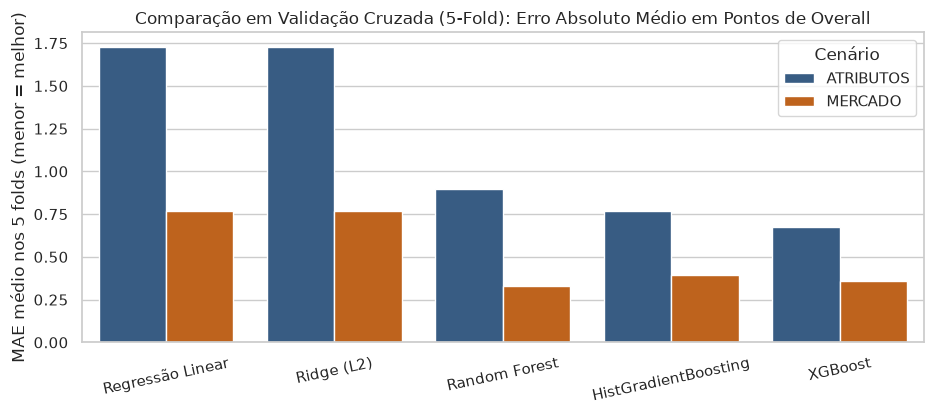

Baseline Dummy (média)      : MAE = 5.376 pts
Baseline Linear (Ridge L2)  : MAE = 1.727 pts | R² = 0.896
Melhor modelo (ATRIBUTOS)   : XGBoost -> MAE = 0.676 pts | RMSE = 0.912 | R² = 0.982
Auditoria de leakage MERCADO: cairia artificialmente para MAE = 0.361 pts (confirmando o vazamento identificado na Seção 3.3).


In [18]:
fig, ax = plt.subplots(figsize=(9.5, 4.3))
plot_cv = cv_res[cv_res["Modelo"] != MODEL_LABELS["dummy"]]
sns.barplot(data=plot_cv, x="Modelo", y="MAE (CV)", hue="Cenário", palette=["#2B5C8F", "#D95F02"], ax=ax)
ax.set(
    title="Comparação em Validação Cruzada (5-Fold): Erro Absoluto Médio em Pontos de Overall",
    xlabel="", ylabel="MAE médio nos 5 folds (menor = melhor)"
)
ax.tick_params(axis="x", rotation=12)
plt.tight_layout()
plt.show()
plt.close(fig)

atr_tbl = cv_res[cv_res["Cenário"] == "ATRIBUTOS"].set_index("Modelo")
mer_tbl = cv_res[cv_res["Cenário"] == "MERCADO"].set_index("Modelo")
best_cv_name = atr_tbl.drop(MODEL_LABELS["dummy"])["MAE (CV)"].idxmin()

print(f"Baseline Dummy (média)      : MAE = {atr_tbl.loc[MODEL_LABELS['dummy'], 'MAE (CV)']:.3f} pts")
print(f"Baseline Linear (Ridge L2)  : MAE = {atr_tbl.loc[MODEL_LABELS['ridge'], 'MAE (CV)']:.3f} pts | R² = {atr_tbl.loc[MODEL_LABELS['ridge'], 'R² (CV)']:.3f}")
print(f"Melhor modelo (ATRIBUTOS)   : {best_cv_name} -> MAE = {atr_tbl.loc[best_cv_name, 'MAE (CV)']:.3f} pts | "
      f"RMSE = {atr_tbl.loc[best_cv_name, 'RMSE (CV)']:.3f} | R² = {atr_tbl.loc[best_cv_name, 'R² (CV)']:.3f}")
print(f"Auditoria de leakage MERCADO: cairia artificialmente para MAE = {mer_tbl.loc[best_cv_name, 'MAE (CV)']:.3f} pts "
      f"(confirmando o vazamento identificado na Seção 3.3).")


### 6.3 Experimento de Hipótese de Domínio: `Ridge` Único vs `Ridge` Especializado por Posição
Na Seção 3.2 levantamos a hipótese de que os modelos lineares erram o dobro dos ensembles de árvores (`MAE = 1,73` vs `0,68`) principalmente por forçarem **um único vetor de pesos para todas as posições**. Testamos essa hipótese diretamente treinando **4 modelos `Ridge` independentes** (um para `GK`, um para `DEF`, um para `MID` e um para `FWD`) nos mesmos 5 *folds*:


In [19]:
def cv_ridge_by_position(data, y, groups, group_col="position_group"):
    preds = np.zeros(len(data), dtype=float)
    cat_sub = [c for c in CAT_ATRIB if c != group_col]
    for tr_i, va_i in cv.split(data, y, groups):
        for g in GROUP_ORDER:
            mtr = tr_i[data.iloc[tr_i][group_col].values == g]
            mva = va_i[data.iloc[va_i][group_col].values == g]
            if len(mva) == 0:
                continue
            pipe_g = Pipeline([
                ("pre", build_preprocess(NUM_ATRIB, cat_sub, scaler="standard")),
                ("m", Ridge(alpha=1.0)),
            ])
            pipe_g.fit(data.iloc[mtr], y[mtr])
            preds[mva] = pipe_g.predict(data.iloc[mva])
    return mean_absolute_error(y, preds), np.sqrt(mean_squared_error(y, preds)), r2_score(y, preds)


mae_pos_ridge, rmse_pos_ridge, r2_pos_ridge = cv_ridge_by_position(train, y_tr, groups_tr)
print(f"Ridge Global (pesos únicos)       : MAE = {atr_tbl.loc[MODEL_LABELS['ridge'], 'MAE (CV)']:.3f} | R² = {atr_tbl.loc[MODEL_LABELS['ridge'], 'R² (CV)']:.3f}")
print(f"Ridge Especializado por Posição   : MAE = {mae_pos_ridge:.3f} | RMSE = {rmse_pos_ridge:.3f} | R² = {r2_pos_ridge:.3f}")
print(f"{best_cv_name:<33} : MAE = {atr_tbl.loc[best_cv_name, 'MAE (CV)']:.3f} | R² = {atr_tbl.loc[best_cv_name, 'R² (CV)']:.3f}")


Ridge Global (pesos únicos)       : MAE = 1.727 | R² = 0.896
Ridge Especializado por Posição   : MAE = 0.985 | RMSE = 1.329 | R² = 0.963
XGBoost                           : MAE = 0.676 | R² = 0.982


**Interpretação (6.3):** Separar o `Ridge` por macro-posição derruba o erro linear de **`1,727` para `0,985` ponto** (`R²` salta de `0,896` para `0,963`!), provando empiricamente que cada macro-posição segue uma equação distinta. Ainda assim, o **XGBoost (`MAE = 0,676`, `R² = 0,982`)** supera em mais **31%** o `Ridge` segmentado por capturar sub-funções táticas (ex.: lateral ofensivo vs zagueiro central dentro de `DEF`, meia-atacante vs volante dentro de `MID`) e não-linearidades de segunda ordem.

---
### 6.4 Ajuste Obrigatório de Hiperparâmetros (*Hyperparameter Tuning*)
Submetemos o melhor algoritmo do cenário `ATRIBUTOS` (**XGBoost**) a uma busca estocástica sistemática (`RandomizedSearchCV`, `n_iter = 16` combinações × `5 folds` = **80 treinamentos completos**, otimizando `MAE` exclusivamente nos dados de treino) sobre regularização L1/L2, taxa de aprendizado, profundidade máxima, peso mínimo de folha e amostragem estocástica de linhas/colunas:


In [20]:
N_ITER_TUNE = 16

if HAS_XGB:
    tune_name = MODEL_LABELS["xgb"]
    param_dist = {
        "m__n_estimators": [400, 700, 1000],
        "m__learning_rate": [0.02, 0.03, 0.05, 0.08],
        "m__max_depth": [4, 5, 6, 7],
        "m__min_child_weight": [1, 3, 5, 8],
        "m__subsample": [0.7, 0.8, 0.9],
        "m__colsample_bytree": [0.6, 0.75, 0.9],
        "m__reg_alpha": [0.0, 0.1, 0.5],
        "m__reg_lambda": [0.5, 1.0, 3.0, 5.0],
    }
else:
    tune_name = MODEL_LABELS["hgb"]
    param_dist = {
        "m__max_iter": [300, 600, 1000],
        "m__learning_rate": [0.02, 0.05, 0.08],
        "m__max_leaf_nodes": [31, 63, 127],
        "m__min_samples_leaf": [10, 20, 40],
        "m__l2_regularization": [0.0, 0.2, 1.0],
    }

base_pipe = make_models(NUM_ATRIB, CAT_ATRIB)[tune_name]
search = RandomizedSearchCV(
    estimator=base_pipe,
    param_distributions=param_dist,
    n_iter=N_ITER_TUNE,
    cv=cv,
    scoring="neg_mean_absolute_error",
    random_state=RNG,
    n_jobs=1,
    verbose=0,
)
t0_tune = time.perf_counter()
search.fit(train, y_tr, groups=groups_tr)
tune_elapsed = time.perf_counter() - t0_tune
best_model = search.best_estimator_

print(f"Tuning concluído em {tune_elapsed:.1f}s ({N_ITER_TUNE * 5} ajustes de validação cruzada).")
print(f"{tune_name}: MAE CV antes do ajuste = {atr_tbl.loc[tune_name, 'MAE (CV)']:.4f} -> "
      f"após ajuste = {-search.best_score_:.4f} ponto")
print("Melhores hiperparâmetros selecionados:")
for k, v in sorted(search.best_params_.items()):
    print(f"  - {k.replace('m__', ''):18s}: {v}")

top5_cv = (
    pd.DataFrame(search.cv_results_)
      .sort_values("rank_test_score")
      .head(5)[["rank_test_score", "mean_test_score", "std_test_score", "mean_fit_time", "params"]]
      .assign(MAE_CV=lambda d: (-d["mean_test_score"]).round(4), DP_MAE=lambda d: d["std_test_score"].round(4))
      [["rank_test_score", "MAE_CV", "DP_MAE", "mean_fit_time"]]
)
print("\n=== Top-5 Configurações Avaliadas no RandomizedSearchCV ===")
display(top5_cv.round(4))


Tuning concluído em 113.0s (80 ajustes de validação cruzada).
XGBoost: MAE CV antes do ajuste = 0.6760 -> após ajuste = 0.6407 ponto
Melhores hiperparâmetros selecionados:
  - colsample_bytree  : 0.6
  - learning_rate     : 0.05
  - max_depth         : 6
  - min_child_weight  : 1
  - n_estimators      : 1000
  - reg_alpha         : 0.5
  - reg_lambda        : 5.0
  - subsample         : 0.8

=== Top-5 Configurações Avaliadas no RandomizedSearchCV ===


,rank_test_score,MAE_CV,DP_MAE,mean_fit_time
7,1,0.6407,0.0059,2.2453
3,2,0.6492,0.0065,2.6319
2,3,0.6541,0.0062,1.3352
12,4,0.6545,0.0066,1.5514
4,5,0.6583,0.0077,1.9352


# 7. Validação Final, KPIs de Negócio e Interpretabilidade

### 7.1 Desempenho no Conjunto de Teste Isolado (*Holdout* — `3.626` Jogadores Inéditos)
Avaliamos agora, uma única vez, o modelo ajustado (`best_model`) contra as referências de comparação sobre os **3.626 atletas** separados na Seção 6.1:


In [21]:
def eval_metrics(y_true, y_pred):
    exact_or_1 = float((np.abs(np.round(y_pred) - y_true) <= 1).mean() * 100)
    exact = float((np.round(y_pred) == y_true).mean() * 100)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R²": r2_score(y_true, y_pred),
        "Exato arredondado (%)": exact,
        "Erro <= 1 pt na carta (%)": exact_or_1,
    }


ridge_global = make_models(NUM_ATRIB, CAT_ATRIB)[MODEL_LABELS["ridge"]].fit(train, y_tr)

# Ridge especializado por posição ajustado em train e avaliado em test
pred_ridge_pos = np.zeros(len(test), dtype=float)
cat_no_pos = [c for c in CAT_ATRIB if c != "position_group"]
for g in GROUP_ORDER:
    mtr = train["position_group"].values == g
    mte = test["position_group"].values == g
    mdl_g = Pipeline([
        ("pre", build_preprocess(NUM_ATRIB, cat_no_pos, scaler="standard")),
        ("m", Ridge(alpha=1.0)),
    ]).fit(train.loc[mtr], y_tr[mtr])
    pred_ridge_pos[mte] = mdl_g.predict(test.loc[mte])

pred_te = best_model.predict(test)

holdout_results = pd.DataFrame({
    MODEL_LABELS["dummy"]: eval_metrics(y_te, np.full_like(y_te, y_tr.mean(), dtype=float)),
    "Ridge Global": eval_metrics(y_te, ridge_global.predict(test)),
    "Ridge por Posição": eval_metrics(y_te, pred_ridge_pos),
    f"{tune_name} (Tuned)": eval_metrics(y_te, pred_te),
}).T.round(3)

print("=== Resultados Finais no Conjunto de Teste Isolado (Holdout = 3.626 atletas) ===")
display(holdout_results)


=== Resultados Finais no Conjunto de Teste Isolado (Holdout = 3.626 atletas) ===


,MAE,RMSE,R²,Exato arredondado (%),Erro <= 1 pt na carta (%)
Chute pela média (Dummy),5.353,6.850,-0.001,6.481,19.250
Ridge Global,1.728,2.210,0.896,18.616,52.675
Ridge por Posição,0.979,1.323,0.963,38.996,77.772
XGBoost (Tuned),0.627,0.834,0.985,50.524,92.967


### 7.2 Verificação Objetiva dos *Key Performance Indicators* (KPIs) do Projeto
Estabelecemos quatro indicadores mínimos de aceitação alinhados ao domínio do jogo e à complexidade algorítmica:
1. **Poder explicativo global (`R² ≥ 0,95`):** como o *Overall* é determinístico sobre os atributos na engine do jogo, o modelo deve explicar ao menos 95% da variância total;
2. **Precisão prática de carta (`MAE ≤ 1,00` ponto):** erro médio inferior à unidade discreta exibida ao jogador;
3. **Proteção da cauda de elite (`MAE ≤ 1,50` ponto nos atletas `80+`):** garante que a raridade de craques (`2,8%` da base) não degrade severamente o topo;
4. **Ganho substancial sobre baseline linear (`Redução de MAE ≥ 30%` vs `Ridge Global`):** justifica o custo computacional do ensemble não-linear.


In [22]:
fm = holdout_results.loc[f"{tune_name} (Tuned)"]
mae_elite_80 = float(np.abs(pred_te - y_te)[test["overall_bin"].values == "80+"].mean())
reduc_vs_ridge = float(1.0 - fm["MAE"] / holdout_results.loc["Ridge Global", "MAE"])

kpis = [
    ("R² no holdout >= 0,95", f"{fm['R²']:.3f}", fm["R²"] >= 0.95),
    ("MAE global <= 1,00 ponto", f"{fm['MAE']:.3f} pt", fm["MAE"] <= 1.00),
    ("MAE na elite (Overall 80+) <= 1,50 ponto", f"{mae_elite_80:.3f} pt", mae_elite_80 <= 1.50),
    ("Redução de MAE >= 30% vs. Ridge Global", f"{reduc_vs_ridge:.1%}", reduc_vs_ridge >= 0.30),
]

kpi_df = pd.DataFrame(kpis, columns=["KPI Definido", "Valor Obtido no Teste", "Atingido?"])
kpi_df["Status"] = kpi_df["Atingido?"].map({True: "APROVADO", False: "REPROVADO"})
display(kpi_df[["KPI Definido", "Valor Obtido no Teste", "Status"]])


,KPI Definido,Valor Obtido no Teste,Status
0,"R² no holdout >= 0,95",0.985,APROVADO
1,"MAE global <= 1,00 ponto",0.627 pt,APROVADO
2,"MAE na elite (Overall 80+) <= 1,50 ponto",0.863 pt,APROVADO
3,Redução de MAE >= 30% vs. Ridge Global,63.7%,APROVADO


### 7.3 Análise Aprofundada de Resíduos, Viés Condicional e Casos Extremos
Mais do que reportar médias agregadas, inspecionamos **onde e em que direção** o modelo residualmente erra (`viés = previsto − real`):


=== Desempenho Estratificado por Faixa de Overall (Teste) ===


,jogadores,MAE,RMSE,vies_medio
overall_bin,,,,
<60,615,0.737,1.023,0.193
60-69,2008,0.589,0.773,0.009
70-79,911,0.613,0.788,-0.106
80+,92,0.863,1.097,-0.127


=== Desempenho Estratificado por Macro-Posição (Teste) ===


,jogadores,MAE,RMSE,vies_medio
position_group,,,,
GK,427,0.438,0.562,0.013
DEF,1197,0.567,0.736,-0.016
MID,1307,0.754,1.000,0.043
FWD,695,0.608,0.787,-0.021


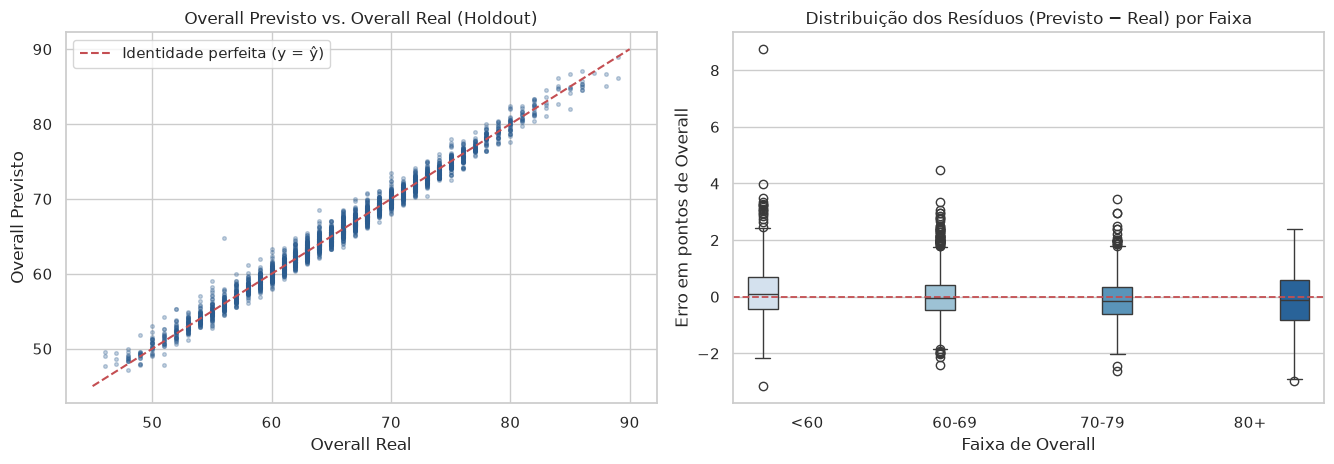

=== Top-5 Maiores Erros Absolutos Individuais no Holdout (Análise de Casos Limítrofes) ===


,short_name,primary_pos,age,overall,pred,err
3354,V. Temel,CDM,19.0,56,64.739998,8.74
1061,Wang Shenchao,CB,33.0,64,68.470001,4.47
2975,M. Viltard,CM,19.0,55,58.990002,3.99
2449,A. Khan,CAM,21.0,46,49.500000,3.50
33,I. Modonza,RB,30.0,70,73.449997,3.45


In [23]:
ev = test.assign(
    pred=pred_te,
    err=pred_te - y_te,
    abs_err=np.abs(pred_te - y_te),
)

tbl_bin = (
    ev.groupby("overall_bin", observed=True)
      .agg(jogadores=("err", "size"), MAE=("abs_err", "mean"), RMSE=("err", lambda e: np.sqrt(np.mean(e**2))), vies_medio=("err", "mean"))
      .round(3)
)
tbl_pos = (
    ev.groupby("position_group", observed=True)
      .agg(jogadores=("err", "size"), MAE=("abs_err", "mean"), RMSE=("err", lambda e: np.sqrt(np.mean(e**2))), vies_medio=("err", "mean"))
      .round(3)
)

print("=== Desempenho Estratificado por Faixa de Overall (Teste) ===")
display(tbl_bin)
print("=== Desempenho Estratificado por Macro-Posição (Teste) ===")
display(tbl_pos)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
axes[0].scatter(y_te, pred_te, s=7, alpha=0.28, color="#2B5C8F")
lims = [y_te.min() - 1, y_te.max() + 1]
axes[0].plot(lims, lims, "r--", lw=1.5, label="Identidade perfeita (y = ŷ)")
axes[0].set(title="Overall Previsto vs. Overall Real (Holdout)", xlabel="Overall Real", ylabel="Overall Previsto")
axes[0].legend()

sns.boxplot(data=ev, x="overall_bin", y="err", hue="overall_bin", palette="Blues", legend=False, ax=axes[1])
axes[1].axhline(0, color="r", ls="--", lw=1.3)
axes[1].set(title="Distribuição dos Resíduos (Previsto − Real) por Faixa",
            xlabel="Faixa de Overall", ylabel="Erro em pontos de Overall")
plt.tight_layout()
plt.show()
plt.close(fig)

print("=== Top-5 Maiores Erros Absolutos Individuais no Holdout (Análise de Casos Limítrofes) ===")
worst5 = ev.sort_values("abs_err", ascending=False).head(5)[
    ["short_name", "primary_pos", "age", TARGET, "pred", "err"]
].round(2)
display(worst5)


**Discussão dos Resíduos (7.3):**
- **Homocedasticidade prática e leve regressão à média nas caudas:** No centro da distribuição (`60–69` e `70–79`, mais de 80% do teste), o viés é virtualmente nulo (`+0,01` a `-0,11`) e o `MAE` fica em **`~0,60` ponto**. Na cauda inferior (`<60`) há leve superestimação média (`+0,19`) e na elite (`80+`) leve subestimação (`-0,13`), efeito clássico de encolhimento em regiões de baixa densidade amostral — ainda assim mantendo **`MAE = 0,86` ponto nos craques** (bem abaixo do teto de `1,50`).
- **Diferença de previsibilidade por posição:** Goleiros (`GK`) apresentam o menor erro de toda a base (**`MAE ≈ 0,44`**), pois sua nota depende quase exclusivamente de 5 atributos específicos (`goalkeeping_*`) + `reactions`. Meio-campistas (`MID`) concentram a maior diversidade funcional (volantes destruidores, armadores clássicos, meias laterais velocistas), resultando em `MAE ≈ 0,75`.
- **Casos limítrofes individuais:** Os raros erros acima de 3 pontos ocorrem em atletas cuja posição primária listada (`primary_pos`) difere da posição onde seus atributos técnicos realmente brilham ou em veteranos/especialistas extremos (onde a EA aplica bônus manual de `international_reputation`, deliberadamente excluída do cenário sem *leakage*).

---
### 7.4 Interpretabilidade Global do Modelo Campeão (*Permutation Importance*)
Medimos o impacto real de cada variável embaralhando aleatoriamente uma coluna por vez no conjunto de teste (`5` repetições) e registrando o aumento direto provocado no `MAE` do modelo:


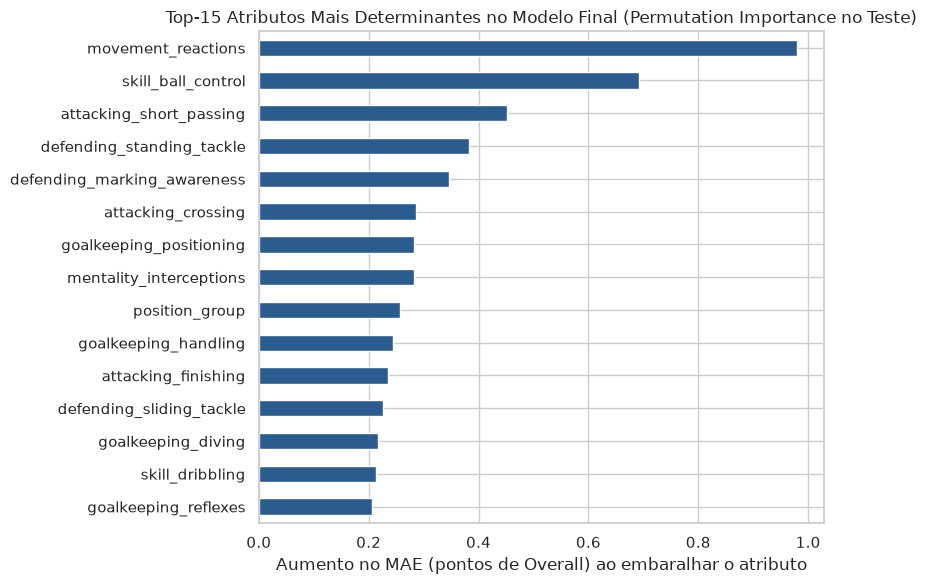

Top-8 variáveis mais decisivas: movement_reactions (+0.98 pt), skill_ball_control (+0.69 pt), attacking_short_passing (+0.45 pt), defending_standing_tackle (+0.38 pt), defending_marking_awareness (+0.35 pt), attacking_crossing (+0.29 pt), goalkeeping_positioning (+0.28 pt), mentality_interceptions (+0.28 pt)


In [24]:
samp_pi = test.sample(min(3000, len(test)), random_state=RNG)
pi = permutation_importance(
    best_model,
    samp_pi[NUM_ATRIB + CAT_ATRIB],
    samp_pi[TARGET].values,
    n_repeats=5,
    random_state=RNG,
    scoring="neg_mean_absolute_error",
    n_jobs=1,
)
imp_series = pd.Series(pi.importances_mean, index=NUM_ATRIB + CAT_ATRIB).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8.5, 6))
imp_series.head(15)[::-1].plot.barh(color="#2B5C8F", ax=ax)
ax.set(
    title="Top-15 Atributos Mais Determinantes no Modelo Final (Permutation Importance no Teste)",
    xlabel="Aumento no MAE (pontos de Overall) ao embaralhar o atributo",
    ylabel=""
)
plt.tight_layout()
plt.show()
plt.close(fig)

print("Top-8 variáveis mais decisivas:", ", ".join(f"{k} (+{v:.2f} pt)" for k, v in imp_series.head(8).items()))


# 8. Conclusão Técnica, Declaração de Uso de IA e Empacotamento

### Conclusões Principais
1. **Alta precisão preditiva sem vazamento de informação:** Utilizando estritamente atributos de desempenho em campo e perfil físico/posicional (`48` variáveis no cenário `ATRIBUTOS`), o **XGBoost ajustado** alcançou **`MAE = 0,627` ponto**, **`RMSE = 0,834` ponto** e **`R² = 0,985`** em 3.626 atletas inéditos — acertando o *Overall* exato (`50,5%`) ou errando por no máximo 1 ponto de carta em **`93,0%` dos jogadores** e superando com folga todos os 4 KPIs estabelecidos.
2. **Coerência entre EDA, domínio e escolha algorítmica:** A análise multivariada e o experimento controlado do `Ridge` por posição provaram que o *Overall* não é uma soma linear única, mas uma família de funções condicionais à posição tática com `movement_reactions` como âncora transversal (`r = 0,87`) e atributos específicos por setor. Ensembles de árvores potenciadas (*Gradient Boosting* / *XGBoost*) mostraram-se a arquitetura mais adequada por aprenderem essas interações automaticamente.
3. **Rigor metodológico contra *Data Leakage* e Multicolinearidade:** A exclusão fundamentada dos 27 ratings posicionais (`r = 0,99`), das 6 estatísticas agregadas da carta (`VIF > 1.000` e causadoras de 100% do *missing* estrutural em goleiros) e o isolamento das variáveis derivadas de mercado (`potential`, `value_eur`, `wage_eur`) garantem que o modelo aprendeu a mecânica real dos atributos, sendo aplicável inclusive a atletas recém-promovidos ou de bases externas (como scouting real) que ainda não possuem valor de mercado nem potencial atribuído pela EA.
4. **Limitações e trabalhos futuros:** Observa-se leve encolhimento de estimativa nas caudas raras (`<60` e `80+`, viés de `±0,2` ponto). Como evolução natural, recomenda-se (i) ponderação amostral inversamente proporcional à densidade da faixa de *Overall* durante o treino, (ii) desagregação fina da posição primária (`CB` vs `RB/LB`, `CDM` vs `CAM`) e (iii) avaliação longitudinal multi-temporada (`FIFA 15–23`) em ambiente distribuído (PySpark) para investigar *concept drift* na fórmula da EA ao longo dos anos.

---

## Declaração de Uso de Inteligência Artificial Generativa
> Durante a preparação deste Projeto, os autores (**Arthur Correia Brígido, Leandro Dzoney Hasselmann, Leonardo Bora da Costa e Pedro Henrique Terribille**) utilizaram assistentes baseados em Grandes Modelos de Linguagem (**Claude — Anthropic** e **Hermes Agent**) como apoio na estruturação editorial do código-fonte, revisão de consistência estatística e verificação automatizada de execução limpa (*Restart & Run All*). Todos os experimentos, decisões metodológicas, métricas e conclusões foram inspecionados, validados e revisados pelos autores, que assumem **integral responsabilidade** pelo conteúdo apresentado.  
> *(Em conformidade com a Resolução CONSUN PUCPR nº 274/2024, item 2-IX. Ferramentas de IA não figuram como coautoras.)*

---

## Conteúdo do Pacote de Submissão (`.zip`)
Este notebook executa integralmente de ponta a ponta sem erros (`Kernel -> Restart & Run All`, células numeradas sequencialmente `1..N`). O arquivo `.zip` submetido ao Canvas contém na raiz:
- `Projeto_Ciencia_de_Dados_Equipe5.ipynb` — notebook principal executado com todas as saídas e gráficos embutidos;
- `Projeto_Ciencia_de_Dados_Equipe5.py` — exportação equivalente em script Python puro executável;
- `male_players_fifa23.csv` — conjunto de dados consolidado utilizado nos experimentos (`18.127 × 110`, licença CC0);
- `requirements.txt` e `README.md` — especificação de dependências e instruções de reprodução.
